## X-Ray Abnormality Detection | DenseNet-169, pretrained on ImageNet

> **Antonopoulos Ilias** ( *p3352004* ) <br />
> **Ndoja Silva** ( *p3352017* ) <br />
> **MSc in Data Science, AUEB**

## Table of Contents

- [Data Loading](#Data-Loading)
 * [Create a tensorflow input pipeline for the training data](#Create-a-tensorflow-input-pipeline-for-the-training-data)
- [DenseNet169 architecture, pretrained on ImageNet](#DenseNet169-architecture,-pretrained-on-ImageNet)

In [1]:
# Gerekli kütüphaneleri içe aktar
import os  # Dosya ve dizin işlemleri için
import pathlib  # Dosya yolu işlemleri için
import random  # Rastgele sayı üretimi için
import re  # Düzenli ifadeler için
from glob import glob  # Dosya eşleştirmesi için

import matplotlib.pyplot as plt  # Grafik çizimi için
import numpy as np  # Sayısal hesaplamalar için
import pandas as pd  # Veri işleme için
import tensorflow as tf  # Derin öğrenme için
from sklearn.metrics import cohen_kappa_score  # Model değerlendirmesi için
from sklearn.utils import shuffle  # Veri karıştırma için

from utils import (  # Yardımcı fonksiyonlar için
    clean_up,  # Veri temizleme fonksiyonu
    F1Score,  # F1 skoru hesaplayan sınıf
    inspect_df,  # Veri çerçevesini inceleyen fonksiyon
    plot_metrics,  # Metrikleri görselleştiren fonksiyon
)

pd.set_option("max_colwidth", None)  # Sütun genişliği ayarı
plt.style.use("dark_background")  # Grafiklerin arka plan stili


In [2]:
pip install tensorflow


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
print(tf.__version__)

2.16.1


In [4]:
# Kullanılabilir GPU sayısını kontrol et ve yazdır
print("Num GPUs Available: ", len(tf.config.list_physical_devices("GPU")))


Num GPUs Available:  0


In [5]:
# GPU'ları listele
gpus = tf.config.experimental.list_physical_devices("GPU")

# GPU belleğini dinamik olarak ayarla
try:
    tf.config.experimental.set_memory_growth(gpus[0], True)
except IndexError:
    # Eğer sistemde GPU yoksa GPU belleğini kısıtlamak mümkün olmayabilir
    print("Cannot memory-restrict the GPU, if no GPU exists in system. Ignore...")
    pass


Cannot memory-restrict the GPU, if no GPU exists in system. Ignore...


In [6]:
# Rastgele sayı üretiminde kullanılacak tohum değerini belirle
SEED = 99910123

# Rastgele sayı üretiminde tekrarlanabilirlik için tohum değerlerini ayarla
os.environ["PYTHONHASHSEED"] = str(SEED)  # Python hash fonksiyonu için
random.seed(SEED)  # Python rastgele modülü için
tf.random.set_seed(SEED)  # TensorFlow için
np.random.seed(SEED)  # NumPy için


### Data Loading

In [7]:
DATASET_DIR = "../data/MURA-v1.1/"

In [8]:
# Rasgele olarak 10 adet PNG dosyası seç
random.choices(glob(os.path.join(DATASET_DIR, "*", "*", "*", "*", "*.png")), k=10)


['../data/MURA-v1.1\\train\\XR_WRIST\\patient08006\\study1_negative\\image2.png',
 '../data/MURA-v1.1\\train\\XR_FINGER\\patient03958\\study1_negative\\image1.png',
 '../data/MURA-v1.1\\valid\\XR_ELBOW\\patient11764\\study1_positive\\image5.png',
 '../data/MURA-v1.1\\train\\XR_SHOULDER\\patient00102\\study1_positive\\image4.png',
 '../data/MURA-v1.1\\train\\XR_ELBOW\\patient06104\\study1_negative\\image3.png',
 '../data/MURA-v1.1\\train\\XR_WRIST\\patient08538\\study1_negative\\image4.png',
 '../data/MURA-v1.1\\train\\XR_FINGER\\patient03987\\study1_negative\\image2.png',
 '../data/MURA-v1.1\\train\\XR_WRIST\\patient07290\\study1_positive\\image1.png',
 '../data/MURA-v1.1\\train\\XR_ELBOW\\patient04933\\study1_positive\\image1.png',
 '../data/MURA-v1.1\\train\\XR_SHOULDER\\patient00070\\study1_positive\\image2.png']

So, the data structure is the following:

```

└─train {data subset}
│   └───XR_ELBOW {study type}
│       │  └───patient00011 {patient}
│       │         └───study1_negative {study with label}
│       │               └───image1.png {view}
│       │               └───image2.png 
│       │               └───image3.png 
                        └───...
   ...
   

└─valid {data subset}
│   └───XR_HUMERUS {study type}
│       │  └───patient11216 {patient}
│       │         └───study1_negative {study with label}
│       │               └───image1.png {view}
│       │               └───image2.png 
                        └───...
```

In [9]:
# Veri kümesindeki PNG görüntülerini say
image_count = len(list(pathlib.Path(DATASET_DIR).glob("*/*/*/*/*.png")))

# Bulunan toplam PNG görüntü sayısını yazdır
print(f"Total PNG images found in dir <{DATASET_DIR}>: {image_count}")


Total PNG images found in dir <../data/MURA-v1.1/>: 40009


We will start by creating a tabular form of the training data (with no actual image files), in order to quickly analyze them. A proper data loader (of the actual image files) will be implemented after that, in a tensorflow-friendly manner.

In [10]:
# Eğitim veri seti görüntü yollarını içeren CSV dosyasını oku
train_image_paths = pd.read_csv(
    os.path.join(DATASET_DIR, "train_image_paths.csv"),  # CSV dosyasının yolu
    names=["image_path"],  # Sütun adları
    header=None,  # Başlık yok
    index_col=False,  # İndeks sütunu yok
)

# Veri çerçevesini incele
inspect_df(train_image_paths)


şekil: (36808, 1)


,image_path
0,MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image1.png
1,MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image2.png
2,MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image3.png
3,MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/image1.png
4,MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/image2.png


In [11]:
# Görüntü yollarını '../data/' diziniyle birleştir
train_image_paths["image_path"] = train_image_paths["image_path"].map(
    lambda x: os.path.join("../data/", x)
)

# Görüntü yollarından study_type bilgisini çıkar
train_image_paths["study_type"] = train_image_paths["image_path"].map(
    lambda x: x.split("/")[4]
)

# Görüntü yollarından patient bilgisini çıkar
train_image_paths["patient"] = train_image_paths["image_path"].map(
    lambda x: x.split("/")[5]
)

# Görüntü yollarından study bilgisini çıkar
train_image_paths["study"] = train_image_paths["image_path"].map(
    lambda x: x.split("/")[6]
)

# Görüntü yollarındaki 'image\d+.png' desenlerini silerek study_path oluştur
train_image_paths["study_path"] = train_image_paths["image_path"].map(
    lambda x: re.sub(r"image\d+.png", "", x)
)


In [12]:
inspect_df(train_image_paths)

şekil: (36808, 5)


,image_path,study_type,patient,study,study_path
0,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image1.png,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/
1,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image2.png,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/
2,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image3.png,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/
3,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/image1.png,XR_SHOULDER,patient00002,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/
4,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/image2.png,XR_SHOULDER,patient00002,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/


In [13]:
train_labeled_studies = pd.read_csv(  # CSV dosyasını oku ve bir DataFrame oluştur
    os.path.join(DATASET_DIR, "train_labeled_studies.csv"),  # CSV dosyasının yolunu oluştur
    names=["study_path", "label"],  # Sütun isimlerini belirle
    header=None,  # CSV dosyasının başlık satırı olmadığını belirt
    index_col=False,  # CSV dosyasındaki veriler için indeks sütunu kullanma
)

inspect_df(train_labeled_studies)  # DataFrame'i incele


şekil: (13457, 2)


,study_path,label
0,MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/,1
1,MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/,1
2,MURA-v1.1/train/XR_SHOULDER/patient00003/study1_positive/,1
3,MURA-v1.1/train/XR_SHOULDER/patient00004/study1_positive/,1
4,MURA-v1.1/train/XR_SHOULDER/patient00005/study1_positive/,1


In [14]:
train_labeled_studies["study_path"] = train_labeled_studies["study_path"].map(  # "study_path" sütunundaki her bir değeri güncelle
    lambda x: os.path.join("../data/", x)  # Her "study_path" değerinin başına "../data/" ekle
)
train_labeled_studies["label"] = train_labeled_studies["label"].map(str)  # "label" sütunundaki her bir değeri string'e çevir


In [15]:
inspect_df(train_labeled_studies)  # train_labeled_studies DataFrame'ini incele


şekil: (13457, 2)


,study_path,label
0,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/,1
1,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/,1
2,../data/MURA-v1.1/train/XR_SHOULDER/patient00003/study1_positive/,1
3,../data/MURA-v1.1/train/XR_SHOULDER/patient00004/study1_positive/,1
4,../data/MURA-v1.1/train/XR_SHOULDER/patient00005/study1_positive/,1


In [16]:
# train_image_paths ve train_labeled_studies DataFrame'lerini "study_path" sütunu üzerinden birleştir
ref_trainset = pd.merge(
    train_image_paths, train_labeled_studies, how="inner", on="study_path"  # "study_path" sütununa göre iç birleşim yap
)

# ref_trainset DataFrame'ini incele
inspect_df(ref_trainset)


şekil: (36808, 6)


,image_path,study_type,patient,study,study_path,label
0,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image1.png,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/,1
1,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image2.png,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/,1
2,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/image3.png,XR_SHOULDER,patient00001,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00001/study1_positive/,1
3,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/image1.png,XR_SHOULDER,patient00002,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/,1
4,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/image2.png,XR_SHOULDER,patient00002,study1_positive,../data/MURA-v1.1/train/XR_SHOULDER/patient00002/study1_positive/,1


#### Create a tensorflow input pipeline for the training data

In [17]:
IMAGE_WIDTH = 224
IMAGE_HEIGHT = 224

Since image directory follows a specific ontological structure (7 upper extremities aka study types) we will shuffle the training dataset beforehand in order to ensure that the validation set will be representable of all study types. 

This is due to the fact that tf.keras `tf.keras.preprocessing.image.ImageDataGenerator` first performs the train-val split and then shuffles per epoch by default.

In [18]:
# ref_trainset DataFrame'ini karıştır
ref_trainset = shuffle(ref_trainset, random_state=SEED)  # random_state kullanarak yeniden üretilebilir sonuçlar elde et


In [19]:
# ImageDataGenerator nesnesi oluştur
training = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=30,  # Görüntüleri 30 dereceye kadar rastgele döndür
    horizontal_flip=True,  # Görüntüleri yatay olarak rastgele çevir
    fill_mode="constant",  # Dönüşümlerde oluşan boşlukları sabit bir değerle doldur
    cval=0.0,  # Boşluklar için doldurma değeri olarak 0 kullan
    validation_split=0.2,  # Eğitim ve doğrulama verileri arasında %80-%20 oranında bölme yap
    preprocessing_function=tf.keras.applications.densenet.preprocess_input,  # DenseNet modeline uygun ön işleme fonksiyonunu kullan
)


In [20]:
# DataFrame'den veri akışı oluştur
trainset = training.flow_from_dataframe(
    dataframe=ref_trainset,  # Kullanılacak DataFrame
    x_col="image_path",  # Görüntülerin dosya yolu sütunu
    y_col="label",  # Etiketlerin sütunu
    target_size=(IMAGE_WIDTH, IMAGE_HEIGHT),  # Hedef boyut
    class_mode="binary",  # İkili sınıflandırma kullan
    batch_size=8,  # Mini toplu boyutu
    seed=SEED,  # Rastgele durum için tohum değeri
    shuffle=True,  # Veri setini karıştır
    subset="training",  # Eğitim alt kümesi
)


Found 29447 validated image filenames belonging to 2 classes.


In [21]:
# DataFrame'den doğrulama veri akışı oluştur
validationset = training.flow_from_dataframe(
    dataframe=ref_trainset,  # Kullanılacak DataFrame
    x_col="image_path",  # Görüntülerin dosya yolu sütunu
    y_col="label",  # Etiketlerin sütunu
    target_size=(IMAGE_WIDTH, IMAGE_HEIGHT),  # Hedef boyut
    class_mode="binary",  # İkili sınıflandırma kullan
    batch_size=8,  # Mini toplu boyutu
    seed=SEED,  # Rastgele durum için tohum değeri
    shuffle=False,  # Veri setini karıştırma
    subset="validation",  # Doğrulama alt kümesi
)


Found 7361 validated image filenames belonging to 2 classes.


### DenseNet169 architecture, pretrained on ImageNet

In [22]:
# Farklı metrikleri içeren bir liste oluştur
METRICS = [
    tf.keras.metrics.TruePositives(name="tp"),  # Doğru pozitif sayısını hesaplar
    tf.keras.metrics.FalsePositives(name="fp"),  # Yanlış pozitif sayısını hesaplar
    tf.keras.metrics.TrueNegatives(name="tn"),  # Doğru negatif sayısını hesaplar
    tf.keras.metrics.FalseNegatives(name="fn"),  # Yanlış negatif sayısını hesaplar
    tf.keras.metrics.BinaryAccuracy(name="binary_acc"),  # İkili doğruluk hesaplar
    tf.keras.metrics.Precision(name="precision"),  # Kesinlik hesaplar
    tf.keras.metrics.Recall(name="recall"),  # Duyarlılık hesaplar
    F1Score(name="f1_score"),  # F1 skoru hesaplar
    tf.keras.metrics.AUC(name="roc_auc", curve="ROC"),  # ROC altında alan hesaplar
    tf.keras.metrics.AUC(name="pr_auc", curve="PR"),  # Precision-Recall altında alan hesaplar
]


In [23]:
"""
"Densely Connected Convolutional Networks" makalesinde tanımlanan Densenet-169 modeli.

Özellik çıkarma için maksimum havuzlamayı tercih edeceğiz, çünkü görüntü üzerindeki herhangi keskin özellikleri 
(vücuda yerleştirilmiş bir donanım gibi) "vurgulamak" istiyoruz, bu kesinlikle anormallikleri gösterecektir.
"""
densenet = tf.keras.applications.densenet.DenseNet169(
    include_top=False,  # ağın üst kısmında tam bağlantılı katmanı dahil etme
    weights="imagenet",
    input_shape=(IMAGE_WIDTH, IMAGE_HEIGHT, 3),
    pooling="max",  # özellik çıkarma için havuzlama modu
    classes=2,
)


In [24]:
def make_densenet_model(
    base_model: tf.keras.applications.densenet.DenseNet169,
) -> tf.keras.Model:
    """
    DenseNet169 tabanlı bir model oluşturur ve döndürür.

    Parametreler:
        base_model: Önceden eğitilmiş DenseNet169 modeli.

    Returns:
        Oluşturulan model.
    """

    # Temel modeli dondur
    base_model.trainable = False

    # Giriş katmanı
    inputs = tf.keras.Input(shape=(IMAGE_WIDTH, IMAGE_HEIGHT, 3))

    # Base modelden gelen çıkışlar
    x = base_model(inputs, training=False)

    # Dropout katmanı
    x = tf.keras.layers.Dropout(rate=0.2)(x)

    # Çıkış katmanı
    output = tf.keras.layers.Dense(units=1, activation="sigmoid")(x)

    # Model oluştur
    model = tf.keras.Model(inputs, output)

    # Modeli derle
    model.compile(
        # Optimizasyon algoritması: Adam optimizer kullanılıyor, düşük bir öğrenme oranı seçiliyor
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
        # Kayıp fonksiyonu: Binary Crossentropy
        loss=tf.keras.losses.BinaryCrossentropy(),
        # Metrikler: Özel olarak tanımlanan METRICS listesi kullanılıyor
        metrics=METRICS,
    )

    return model


In [25]:
model = make_densenet_model(base_model=densenet)

In [26]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet169 (Functional)        │ (None, 1664)           │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1664)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,665 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,644,545 (48.24 MB)

 Trainable params: 1,665 (6.50 KB)

 Non-trainable params: 12,642,880 (48.23 MB)

In [27]:
pip install graphviz


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


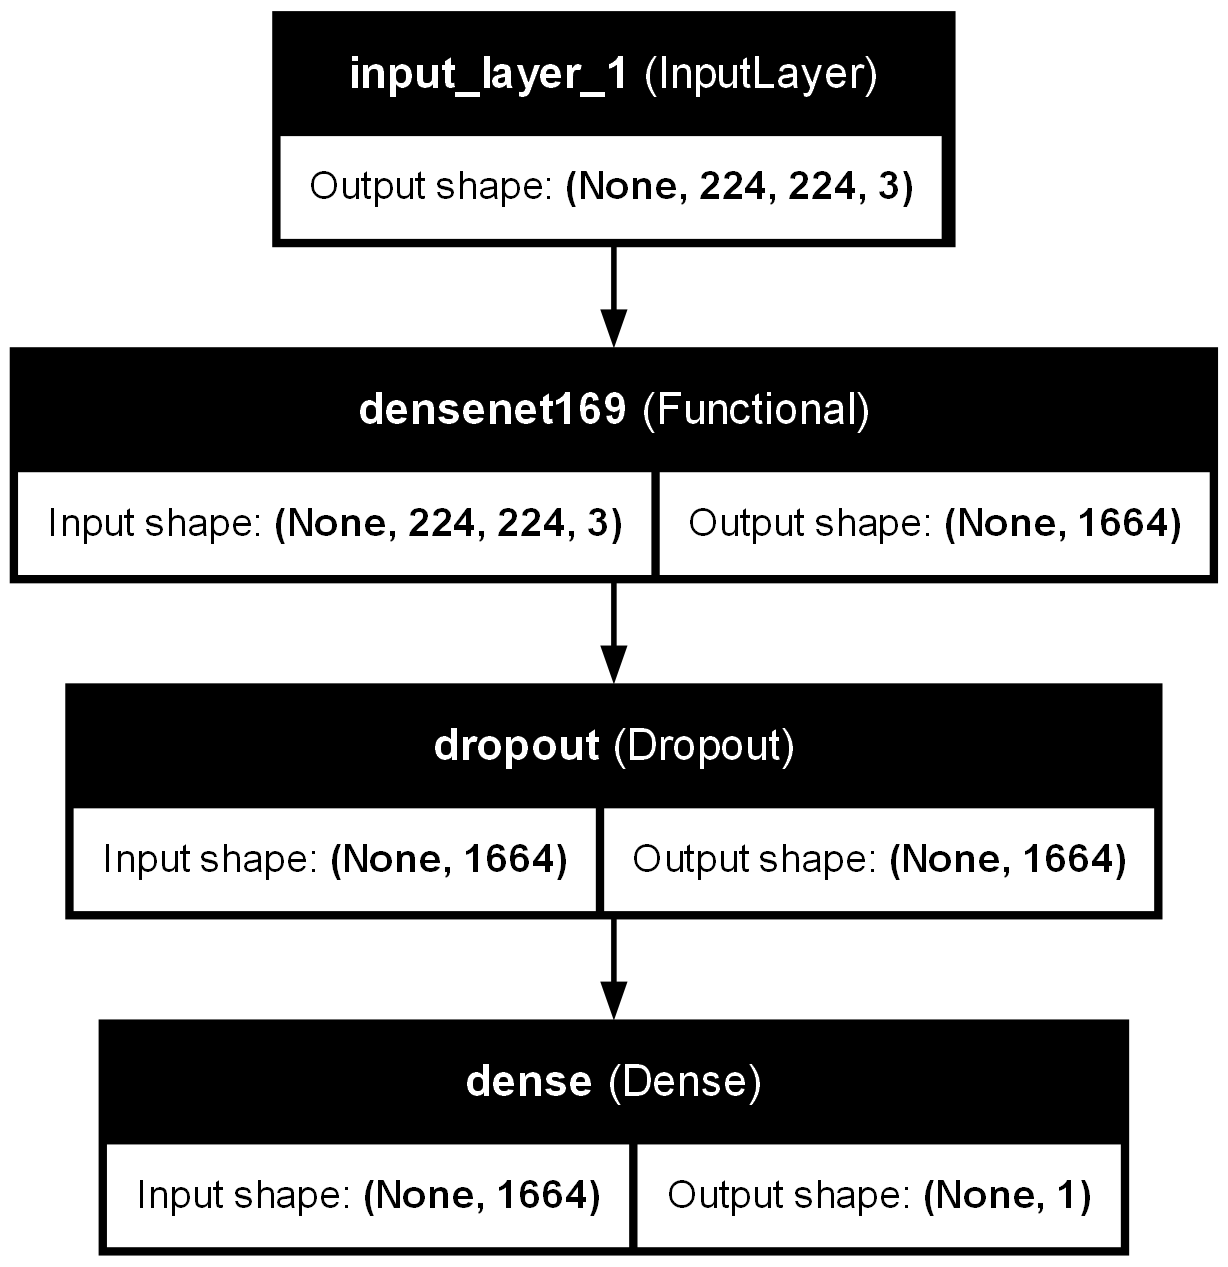

In [28]:
# Modelin görsel temsili oluşturuluyor ve ../static dizinine kaydediliyor
tf.keras.utils.plot_model(
    model,
    # Oluşturulan görselin dosya yolunu ve adını belirtiyoruz
    to_file=f"../static/densenet169_pt_imagenet-tüm-çalışma-tipleri-{model.count_params()}.png",
    # Şekilleri (katmanları) göster
    show_shapes=True,
    # Katman adlarını göster
    show_layer_names=True,
)


In [29]:
# Erken durdurma geri çağırıcısını tanımlayalım
early_stopping = tf.keras.callbacks.EarlyStopping(
    # İzlenecek metrik: validation setindeki Cohen Kappa puanı
    monitor="val_cohen_kappa",
    # Çıktıları göster
    verbose=1,
    # Sabır seviyesi: Eğer monitör edilen metrik belirtilen sayıda epok boyunca iyileşmezse eğitimi durdur
    patience=5,
    # İzleme modu: "max" seçildi, yani monitör edilen metrik maksimize edilmeye çalışılacak
    mode="max",
    # Baz çizgi: Eğer monitör edilen metrik bu değeri aşarsa, eğitimi durdurma işlemi gerçekleşmeyecek
    baseline=0.0,
    # En iyi ağırlıkları geri yükleme: Eğitim sırasında en iyi ağırlıkları geri yükle
    restore_best_weights=True,
)


In [30]:
# Modeli eğit
history = model.fit(
    # Eğitim veri setini kullanarak modeli eğit
    trainset,
    # 4 epok boyunca eğitim gerçekleştir
    epochs=4,
    # Doğrulama veri setini kullanarak modelin performansını değerlendir
    validation_data=validationset,
    # Erken durdurma geri çağrıcısını kullanarak eğitimi kontrol et
    callbacks=[early_stopping],
)


Epoch 1/4


C:\Users\tosh\AppData\Roaming\Python\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


3681/3681 ━━━━━━━━━━━━━━━━━━━━ 5990s 2s/step - binary_acc: 0.5480 - f1_score: 0.4187 - fn: 3381.1211 - fp: 3080.3540 - loss: 1.1429 - pr_auc: 0.4283 - precision: 0.4301 - recall: 0.4079 - roc_auc: 0.5344 - tn: 5716.8828 - tp: 2552.7898 - val_binary_acc: 0.6545 - val_f1_score: 0.5550 - val_fn: 1356.0000 - val_fp: 1187.0000 - val_loss: 0.6597 - val_pr_auc: 0.6101 - val_precision: 0.5719 - val_recall: 0.5391 - val_roc_auc: 0.6941 - val_tn: 3232.0000 - val_tp: 1586.0000
Epoch 2/4


C:\Users\tosh\AppData\Roaming\Python\Python311\site-packages\keras\src\callbacks\early_stopping.py:155: UserWarning: Early stopping conditioned on metric `val_cohen_kappa` which is not available. Available metrics are: binary_acc,f1_score,fn,fp,loss,pr_auc,precision,recall,roc_auc,tn,tp,val_binary_acc,val_f1_score,val_fn,val_fp,val_loss,val_pr_auc,val_precision,val_recall,val_roc_auc,val_tn,val_tp
  current = self.get_monitor_value(logs)


3681/3681 ━━━━━━━━━━━━━━━━━━━━ 8641s 2s/step - binary_acc: 0.6384 - f1_score: 0.5401 - fn: 2887.9946 - fp: 2338.2993 - loss: 0.7449 - pr_auc: 0.5902 - precision: 0.5664 - recall: 0.5163 - roc_auc: 0.6688 - tn: 6379.8462 - tp: 3124.9092 - val_binary_acc: 0.6990 - val_f1_score: 0.4984 - val_fn: 1841.0000 - val_fp: 375.0000 - val_loss: 0.6061 - val_pr_auc: 0.6797 - val_precision: 0.7459 - val_recall: 0.3742 - val_roc_auc: 0.7460 - val_tn: 4044.0000 - val_tp: 1101.0000
Epoch 3/4
3681/3681 ━━━━━━━━━━━━━━━━━━━━ 4394s 1s/step - binary_acc: 0.6841 - f1_score: 0.5752 - fn: 2736.3203 - fp: 1939.4215 - loss: 0.6265 - pr_auc: 0.6436 - precision: 0.6201 - recall: 0.5364 - roc_auc: 0.7202 - tn: 6862.2129 - tp: 3193.4158 - val_binary_acc: 0.7185 - val_f1_score: 0.5894 - val_fn: 1455.0000 - val_fp: 617.0000 - val_loss: 0.5581 - val_pr_auc: 0.7068 - val_precision: 0.7067 - val_recall: 0.5054 - val_roc_auc: 0.7662 - val_tn: 3802.0000 - val_tp: 1487.0000
Epoch 4/4
3681/3681 ━━━━━━━━━━━━━━━━━━━━ 4400s 1s/

KeyError: 'cohen_kappa'

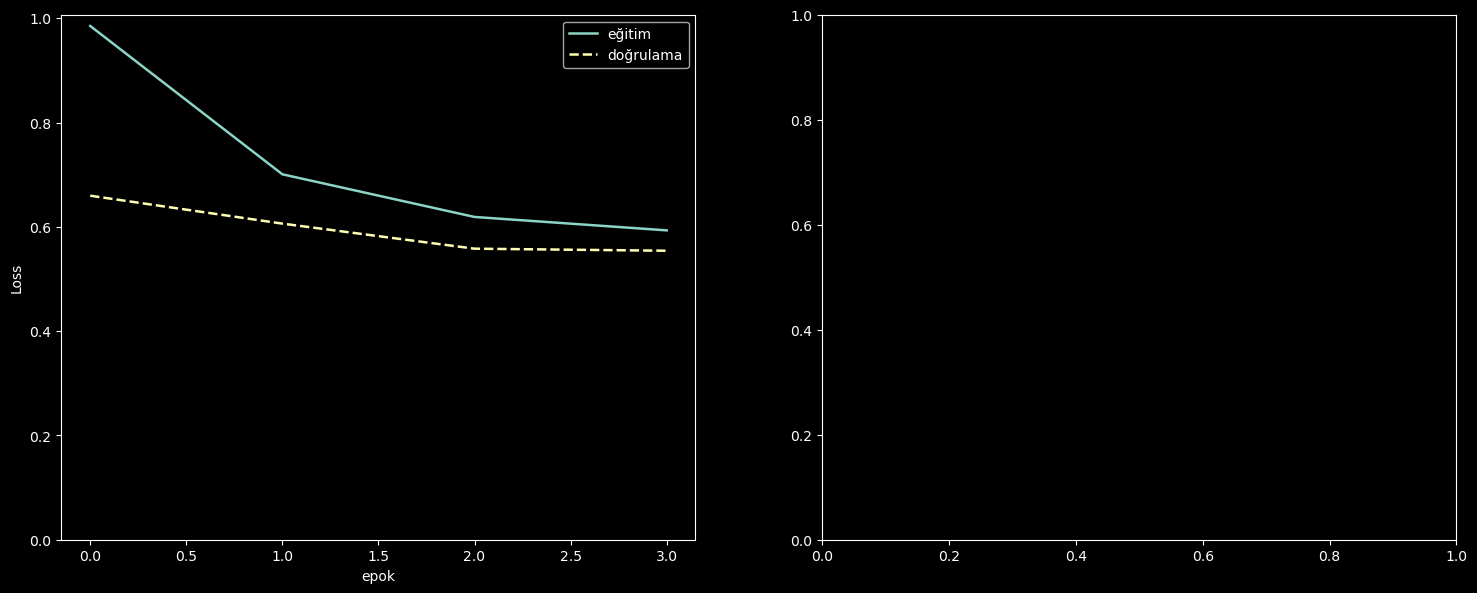

In [33]:
plot_metrics(history)

In [34]:
# model isimlendirme kuralı: {mimari}-{hangi-çalışma-tipi?}-{parametre-sayısı}.h5
#
# Modelleri yüklemek için:
# model = tf.keras.models.load_model(
#     '../models/densenet169_pt_imagenet-tüm-çalışma-tipleri-?.h5',
#     custom_objects={'F1Score': F1Score}
# )
# densenet = tf.keras.models.load_model(
#     '../models/densenet169_baz.h5',
# )
print(
    f"Kaydediliyor: ../models/densenet169_pt_imagenet-tüm-çalışma-tipleri-{model.count_params()}.h5"
)
model.save(
    f"../models/densenet169_pt_imagenet-tüm-çalışma-tipleri-{model.count_params()}.h5"
)
densenet.save("../models/densenet169_baz.h5")


Saving: ../models/densenet169_pt_imagenet-all-study-types-12644545.h5


In [35]:
# İnce ayarlama: temel modelin dondurulması ve düşük bir öğrenme oranıyla tüm modelin sonundan sona eğitilmesi
densenet.trainable = True

# Modeli derle
model.compile(
    # Optimizasyon algoritması: Adam optimizer kullanılıyor, düşük bir öğrenme oranı seçiliyor
    optimizer=tf.keras.optimizers.Adam(
        1e-5
    ),  # Kritik unutmayı önlemek için küçük bir öğrenme oranı kullanılıyor
    # Kayıp fonksiyonu: Binary Crossentropy
    loss=tf.keras.losses.BinaryCrossentropy(),
    # Metrikler: Özel olarak tanımlanan METRICS listesi kullanılıyor
    metrics=METRICS,
)


In [36]:
# ReduceLROnPlateau geri çağırıcısını tanımla
reduce_lr_on_plateau = tf.keras.callbacks.ReduceLROnPlateau(
    # Izlenecek metrik: validation setinde Cohen Kappa puanı
    monitor="val_cohen_kappa",
    # Çıktıları göster
    verbose=1,
    # Sabır seviyesi: Eğer monitör edilen metrik belirtilen sayıda epok boyunca iyileşmezse öğrenme oranını azalt
    patience=4,
    # İzleme modu: "max" seçildi, yani monitör edilen metrik maksimize edilmeye çalışılacak
    mode="max",
    # Azalma oranı: öğrenme oranını azaltmak için kullanılan çarpan
    factor=0.2,
    # Minimum öğrenme oranı
    min_lr=1e-10,
)


In [39]:
history = model.fit(
    # Eğitim veri setini kullanarak modeli eğit
    trainset,
    # 10 epok boyunca eğitim gerçekleştir
    epochs=10,
    # Doğrulama veri setini kullanarak modelin performansını değerlendir
    validation_data=validationset,
    # Erken durdurma ve azalan öğrenme hızı gibi geri çağrıları kullanarak eğitimi kontrol et
    callbacks=[early_stopping, reduce_lr_on_plateau],
)


Epoch 1/10
3681/3681 ━━━━━━━━━━━━━━━━━━━━ 16585s 5s/step - binary_acc: 0.6752 - f1_score: 0.5822 - fn: 2620.7083 - fp: 1967.3843 - loss: 0.6349 - pr_auc: 0.6485 - precision: 0.6124 - recall: 0.5558 - roc_auc: 0.7174 - tn: 6801.3975 - tp: 3342.1523 - val_binary_acc: 0.7708 - val_f1_score: 0.6702 - val_fn: 1228.0000 - val_fp: 459.0000 - val_loss: 0.5002 - val_pr_auc: 0.7937 - val_precision: 0.7888 - val_recall: 0.5826 - val_roc_auc: 0.8274 - val_tn: 3960.0000 - val_tp: 1714.0000 - learning_rate: 1.0000e-05
Epoch 2/10


C:\Users\tosh\AppData\Roaming\Python\Python311\site-packages\keras\src\callbacks\callback_list.py:96: UserWarning: Learning rate reduction is conditioned on metric `val_cohen_kappa` which is not available. Available metrics are: binary_acc,f1_score,fn,fp,loss,pr_auc,precision,recall,roc_auc,tn,tp,val_binary_acc,val_f1_score,val_fn,val_fp,val_loss,val_pr_auc,val_precision,val_recall,val_roc_auc,val_tn,val_tp,learning_rate.
  callback.on_epoch_end(epoch, logs)


3681/3681 ━━━━━━━━━━━━━━━━━━━━ 15365s 4s/step - binary_acc: 0.7393 - f1_score: 0.6535 - fn: 2245.9465 - fp: 1528.1969 - loss: 0.5453 - pr_auc: 0.7471 - precision: 0.6992 - recall: 0.6135 - roc_auc: 0.7957 - tn: 7265.4888 - tp: 3691.3972 - val_binary_acc: 0.7977 - val_f1_score: 0.7134 - val_fn: 1089.0000 - val_fp: 400.0000 - val_loss: 0.4696 - val_pr_auc: 0.8201 - val_precision: 0.8225 - val_recall: 0.6298 - val_roc_auc: 0.8497 - val_tn: 4019.0000 - val_tp: 1853.0000 - learning_rate: 1.0000e-05
Epoch 3/10
3681/3681 ━━━━━━━━━━━━━━━━━━━━ 15440s 4s/step - binary_acc: 0.7677 - f1_score: 0.6902 - fn: 2103.0942 - fp: 1304.1022 - loss: 0.5031 - pr_auc: 0.7909 - precision: 0.7445 - recall: 0.6435 - roc_auc: 0.8233 - tn: 7461.9658 - tp: 3861.9495 - val_binary_acc: 0.8004 - val_f1_score: 0.7409 - val_fn: 842.0000 - val_fp: 627.0000 - val_loss: 0.4543 - val_pr_auc: 0.8302 - val_precision: 0.7701 - val_recall: 0.7138 - val_roc_auc: 0.8577 - val_tn: 3792.0000 - val_tp: 2100.0000 - learning_rate: 1.0

In [40]:
# model isimlendirme kuralı: {mimari}-{hangi-çalışma-tipi?}-{parametre-sayısı}.h5
#
# Modelleri yüklemek için:
# model = tf.keras.models.load_model(
#     '../models/densenet169_pt_imagenet-tüm-çalışma-tipleri-?.h5',
#     custom_objects={'F1Score': F1Score}
# )
# densenet = tf.keras.models.load_model(
#     '../models/densenet169_baz.h5',
# )

# Modelin kaydedileceği dosya yolunu yazdır
print(
    f"Kaydediliyor: ../models/densenet169_pt_imagenet-tüm-çalışma-tipleri-{model.count_params()}.h5"
)

# Modeli kaydet
model.save(
    f"../models/densenet169_pt_imagenet-tüm-çalışma-tipleri-{model.count_params()}.h5"
)

# Densenet modelini kaydet
densenet.save("../models/densenet169_baz.h5")


Saving: ../models/densenet169_pt_imagenet-all-study-types-12644545.h5


In [48]:
print(history.history.keys())


dict_keys(['binary_acc', 'f1_score', 'fn', 'fp', 'loss', 'pr_auc', 'precision', 'recall', 'roc_auc', 'tn', 'tp', 'val_binary_acc', 'val_f1_score', 'val_fn', 'val_fp', 'val_loss', 'val_pr_auc', 'val_precision', 'val_recall', 'val_roc_auc', 'val_tn', 'val_tp', 'learning_rate'])


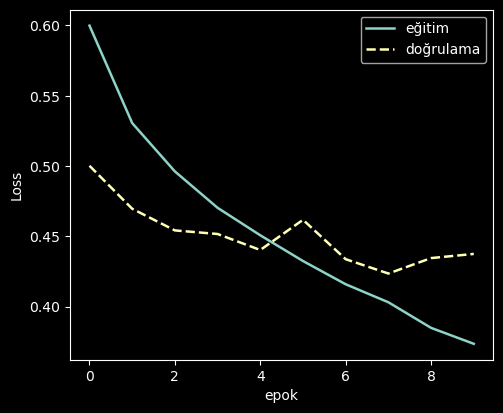

In [49]:
plot_metrics(history)

In [50]:
# Modelin doğrulama modunda kayıp değerini ve metrik değerlerini al
evaluation_metrics = model.evaluate(validationset, verbose=1)


921/921 ━━━━━━━━━━━━━━━━━━━━ 1066s 1s/step - binary_acc: 0.8057 - f1_score: 0.7558 - fn: 386.0759 - fp: 319.8915 - loss: 0.4488 - pr_auc: 0.8489 - precision: 0.7758 - recall: 0.7371 - roc_auc: 0.8664 - tn: 1884.8926 - tp: 1101.1161


In [51]:
# İlk elemanı (kayıp değeri) evaluation_metrics listesinden çıkar ve loss değişkenine ata
loss = evaluation_metrics.pop(0)

# Kayıp değerini yazdır
print(f"val loss    : {loss}")

# METRICS listesi ile evaluation_metrics listesini eşleştir ve metrik adları ile skorları yazdır
for metric, score in zip(METRICS, evaluation_metrics):
    print(f"{metric.name + ' ' * (12 - len(metric.name))}: {score}")


val loss    : 0.43502384424209595
tp          : 2189.0
fp          : 637.0
tn          : 3782.0
fn          : 753.0
binary_acc  : 0.8111669421195984
precision   : 0.7745930552482605
recall      : 0.7440516948699951
f1_score    : <KerasVariable shape=(), dtype=float32, path=f1_score/f1>
roc_auc     : 0.8734627962112427
pr_auc      : 0.8530731797218323


In [52]:
clean_up(model)
clean_up(densenet)